In [8]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch_directml

In [9]:
NUM_DATA_POINTS = 1000
NUM_EPOCHS = 100
LEARNING_RATE = 0.01
# DEVICE = torch_directml.device(0)     torch_directml is not available as it doesn't support all the operations in recurrent layers
DEVICE = torch.device('cpu')

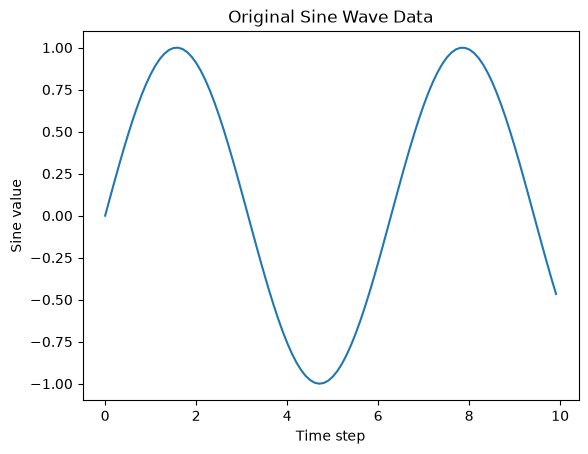

In [10]:
x_values = np.linspace(0, 100, NUM_DATA_POINTS)

# Calculate the sine of each x value to create our time series data
y_values = np.sin(x_values)

# Plot the first 100 points to visualize the generated sine wave
plt.plot(x_values[:100], y_values[:100])
plt.title("Original Sine Wave Data")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.show()

In [11]:
# Function to create sequences (features) and corresponding labels (targets)
def create_sequences(data, sequence_length):
    inputs = []
    targets = []
    
    # Iterate through the data to create sliding windows
    for i in range(len(data) - sequence_length):
        # Extract a window of 'sequence_length' points
        window = data[i:(i + sequence_length)]
        # The target is the immediate next point after the window
        target = data[i + sequence_length]
        
        inputs.append(window)
        targets.append(target)
        
    return np.array(inputs), np.array(targets)

# Set the sequence length (how many past steps the model looks at)
seq_length = 20

# Generate the formatted inputs (X) and targets (y)
X_data, y_target = create_sequences(y_values, seq_length)

# Convert numpy arrays to PyTorch tensors and cast to 32-bit floating point
X_tensor = torch.tensor(X_data, dtype=torch.float32, device=DEVICE)
y_tensor = torch.tensor(y_target, dtype=torch.float32, device=DEVICE)

# Reshape tensors to match PyTorch LSTM expectations: [batch_size, sequence_length, num_features]
# unsqueeze(-1) adds a new dimension at the last position (index -1)
X_tensor = X_tensor.unsqueeze(-1)
y_tensor = y_tensor.unsqueeze(-1)

print(f"Shape of input tensor (X_tensor): {X_tensor.shape}") 
# Expected: torch.Size([980, 20, 1])
print(f"Shape of target tensor (y_tensor): {y_tensor.shape}") 
# Expected: torch.Size([980, 1])

Shape of input tensor (X_tensor): torch.Size([980, 20, 1])
Shape of target tensor (y_tensor): torch.Size([980, 1])


In [12]:
class SineLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, output_size=1):
        super(SineLSTM, self).__init__()
        
        # Store the hidden size for later reference if needed
        self.hidden_size = hidden_size
        
        # Define the LSTM layer
        # batch_first=True tells the model to expect input tensors of shape (batch, seq, feature)
        self.lstm = nn.LSTM(input_size=input_size, 
                            hidden_size=hidden_size, 
                            batch_first=True)
        
        # Define the fully connected (linear) layer to map LSTM output to our single numeric prediction
        self.linear = nn.Linear(in_features=hidden_size, out_features=output_size)

    def forward(self, x):
        # Pass input sequence through the LSTM layer
        # lstm_out contains all hidden states across all time steps
        # We ignore the returned final hidden state and cell state tuples (_)
        lstm_out, _ = self.lstm(x)
        
        # Extract the hidden state from the very last time step of the sequence
        # Syntax means: [all_batches, last_time_step, all_hidden_features]
        last_time_step_out = lstm_out[:, -1, :]
        
        # Map the final hidden state to a single output value
        prediction = self.linear(last_time_step_out)
        
        return prediction

# Instantiate the model
model = SineLSTM().to(DEVICE)
print(model)

SineLSTM(
  (lstm): LSTM(1, 50, batch_first=True)
  (linear): Linear(in_features=50, out_features=1, bias=True)
)


In [13]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [14]:
for epoch in range(NUM_EPOCHS):
    predictions = model(X_tensor)
    loss = criterion(predictions, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{NUM_EPOCHS}], Loss: {loss.item():.6f}')

Epoch [20/100], Loss: 0.006315
Epoch [40/100], Loss: 0.000446
Epoch [60/100], Loss: 0.000110
Epoch [80/100], Loss: 0.000045
Epoch [100/100], Loss: 0.000026
